(seurat-import)=
# Import a saved Seurat object

Import RNA counts, cell metadata and saved PCA and UMAP coordinates from a Seurat RDS file.
This tutorial uses a 1,000-cell PBMC example, followed by a tiny synthetic file that shows
how CyteArc handles skipped metadata and an active SCT assay. No R session is needed.

The PBMC file is Hua Yichao's [SeuratExtend example data](https://zenodo.org/records/10944066),
licensed under CC0 and derived from 10x Genomics data under CC BY 4.0. The synthetic file
was made for CyteArc and uses its BSD-3-Clause license.
See [](../reference/third_party_notices.md) for data credits.

## Download and inspect the PBMC object

Download the file from CyteArc's public example bucket, then check its contents.

In [1]:
# Work with local file paths.
from pathlib import Path

# Keep each import in a fresh directory.
from tempfile import TemporaryDirectory

# Download the example RDS file.
from huggingface_hub import download_bucket_files

# Display inspection results as tables.
import pandas as pd

# Inspect and import Seurat objects.
import cytearc

# Hide routine progress messages.
cytearc.configure_output(level="WARNING", progress=False)

# Show full import notices in the tables below.
pd.set_option("display.max_colwidth", None)

# Choose where to save the downloaded file.
data_directory = Path("cytearc_datasets")

# Create the download directory if needed.
data_directory.mkdir(exist_ok=True)

# Name the local RDS file.
rds_path = data_directory / "seurat_v4_1_3_pbmc_mye.rds"

# Download the public PBMC example.
download_bucket_files(
    "Nygen/cytebase",
    files=[("cytearc_tests/seurat_v4_1_3_pbmc_mye.rds", rds_path)],
    token=False,
    raise_on_missing_files=True,
)

# Keep the converted stores in a temporary directory.
work = TemporaryDirectory()

# Use this directory for each import below.
output_directory = Path(work.name)

Started: 2026-10-23T14:34:31.338706Z | Wall time: 3.334 s

In [2]:
# Inspect the assays, metadata and saved coordinates.
inspection = cytearc.inspect_seurat(rds_path)

# Check that the downloaded file matches the published example.
assert inspection.sourceDigest == "f84adf523a78aeb6e6681cf09e06a2a2fcd4e3fe857fdd89b17e90a1782fac3d"

# Show the active assay and cell count.
print("Active assay:", inspection.activeAssay, "| Cells:", inspection.nCells)

# List the assays and their feature-by-cell dimensions.
pd.DataFrame(inspection.assays, columns=["name", "dimensions", "importable"])

Active assay: RNA | Cells: 1000


,name,dimensions,importable
0,RNA,"(17195, 1000)",True


Started: 2026-10-23T14:34:34.675647Z | Wall time: 1.370 s

In [3]:
# List the saved coordinates, their cell-by-dimension shapes and their roles.
pd.DataFrame(inspection.reductions, columns=["name", "dimensions", "role", "assayUsed"])

,name,dimensions,role,assayUsed
0,pca,"(1000, 50)",graphCoordinates,RNA
1,umap,"(1000, 2)",displayEmbedding,RNA


Started: 2026-10-23T14:34:36.049131Z | Wall time: 0.011 s

In [4]:
# Open the RDS to read its metadata column names.
with cytearc.SeuratReader(rds_path) as reader:

    # Keep the names before closing the reader.
    metadata_names = reader.cellMetadata.columnNames

# Show the columns available for import.
metadata_names

('orig.ident',
 'nCount_RNA',
 'nFeature_RNA',
 'percent.mt',
 'seurat_clusters',
 'cluster')

Started: 2026-10-23T14:34:36.063574Z | Wall time: 0.710 s

## Select metadata and reductions

Keep RNA counts, PCA, UMAP and four metadata columns. `cell_metadata` chooses the columns;
`default_assay` chooses which imported assay later analyses use by default.

Use `reduction_roles` to mark PCA as coordinates for a graph and UMAP as a display layout.
These roles are already recognized in this file, but naming them shows how to override a
role when needed. The coordinates are imported as they are.

In [5]:
# Choose the output store.
pbmc_store = output_directory / "pbmc.zarr"

# Select the counts, metadata and saved coordinates.
with cytearc.SeuratReader(
    rds_path,
    assays=["RNA"],
    reductions=["pca", "umap"],
    cell_metadata=["orig.ident", "nCount_RNA", "nFeature_RNA", "percent.mt"],
    reduction_roles={"pca": "coordinates", "umap": "umap"},
) as reader:

    # Write the store with RNA as its default assay.
    imported = cytearc.SeuratToZarr(
        reader, zarr_loc=str(pbmc_store), default_assay="RNA",
        nthreads=4, mem_budget="4G",
    ).dump()

# Show the imported assays and default.
print("Imported assays:", imported.assayNames, "| Default:", imported.defaultAssay)

# Show what the import left out.
pd.DataFrame(imported.notices, columns=["code", "objectPath", "message"])

Imported assays: ('RNA',) | Default: RNA


,code,objectPath,message
0,ignored_seurat_slot,commands,Seurat slot 'commands' is not imported
1,ignored_normalized_layer,assays/RNA/data,normalized slot 'data' is not imported
2,ignored_normalized_layer,assays/RNA/scale.data,normalized slot 'scale.data' is not imported
3,ignored_assay_slot,assays/RNA/var.features,assay slot 'var.features' is not imported
4,ignored_reduction_slot,reductions/pca/misc,reduction slot 'misc' is not imported


Started: 2026-10-23T14:34:36.776823Z | Wall time: 5.413 s

The `commands` notice says that Seurat's command history was omitted. Counts, selected
metadata, identities and coordinates were imported. Review these notices to see which
parts of your source object were kept.

In [6]:
# Open the imported store without filtering its cells.
ds = cytearc.DataStore(str(pbmc_store), min_features_per_cell=-1, nthreads=4)

# Inspect the imported cell and feature counts.
ds

DataStore has 1000 (1000) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo', 'nCount_RNA', 'nFeature_RNA', 'orig.ident', 
            'percent.mt'
   RNA assay has 17195 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'nCells', 
            'vst.mean', 'vst.variable', 'vst.variance', 'vst.variance.expected', 'vst.variance.standardized'

Started: 2026-10-23T14:34:42.194696Z | Wall time: 2.002 s

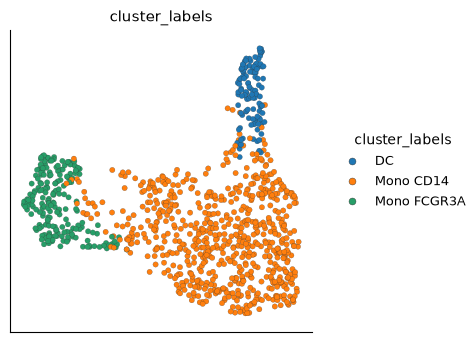

Started: 2026-10-23T14:34:44.200005Z | Wall time: 1.564 s

In [7]:
# Plot the saved Seurat UMAP using the saved active identities.
ds.plots.embedding(
    layout=imported.reductionArtifacts["umap"],
    color_by=imported.activeIdentity,
)

Pass the imported layout and identities directly to `plots.embedding`, as above. To build
a graph from the saved PCA, pass `imported.reductionArtifacts["pca"]` to
`ds.graph.ann_index`; see [](graph_construction.ipynb).

## Read partial-import notices

The PBMC file has no unsupported metadata or SCT assay. The small file below adds a
list-valued `notes` column, an active SCT assay derived from RNA, and coordinates called
`layout`. Its three cells and two genes are synthetic. The file is embedded in the
notebook so this example also works in the downloaded copy.

In [8]:
# Decode the embedded example file.
import base64

# Choose a path for the synthetic RDS.
partial_path = output_directory / "partial.rds"

# Write the embedded bytes to that path.
partial_path.write_bytes(base64.b64decode(
    'H4sIAAAAAAAC/+1VT2+bMBQ3EGhAY4u0HdoPMaRml92WqtNu26HtpN6iF3AjNBtXYLLlW+8TVLXD'
    'MyXUJFSbtMsiOX62f+/5/fn5cRsRQjwymah/X4nE/37z5f1HtTojZOKqDUeNUI0Aqgq2FSHuW7Vy'
    'bYhU1IXUiFivSPNzGrS6pF3vaXlZztUUIwyhe5CpghTAqTJN8HIyw1mfu+vzVprjmWd20vYsnbfS'
    'h94NfspUeD2zAQdZ5r8MBMoStkp46OnGnEpI7ijIuqQmP6R/gfF/ZjkMS/Ez6QIGAht22WxGGWhf'
    'SmXL4qlVxb/QdW3QI0rq2sf/kv6bksbXlzdfRUZZwvJKoqeOpZJhzfMEsNRd+97Vt4sxfkzNTTZi'
    'dSNtN/kQesh8h4nD5t09vxtR6VrUwl0VdfowL16PSGEK97rCSxi1EaOqtu/j3DVrPHOMtrPqBemk'
    'A3TZi9C4F1TA7xk1PCgu9VtcPoXtF0JqpcPE+4NXM46CryCV+YbaybWrjBWeZ7SQ2FhMVh3L9yFg'
    'dENZ3yUPGBvjenCnrhPlmHQPJuhZxFFJs1pFIYrqwIt7k1LGEspXNMvyYq2hr7VHn343BFjgB3Ex'
    'xRmJsXiH8ykCDjZXz9J/h5rr8Ui7NJ6mdSUFX5731vO/2Ghn2GMTJqCbpCNB2/JiC/rhWPd5obvR'
    'juNJXdHseBcN1kysQDfACHefvfpKZnSjBGvIP2j/NZ1gBUb10885v9I0HduuAwZbUcux/Tq4pnUJ'
    'O/gjxAGVbkQKAAA='
))

581

Started: 2026-10-23T14:34:45.766877Z | Wall time: 0.009 s

In [9]:
# Inspect the small file before importing it.
partial_inspection = cytearc.inspect_seurat(partial_path)

# Show its active assay.
print("Active assay:", partial_inspection.activeAssay)

# Show the role inferred for the coordinates called layout.
print("Inferred role:", partial_inspection.reductions[0].role)

# Show which metadata could not be read.
pd.DataFrame(
    partial_inspection.cellMetadata.notices, columns=["code", "objectPath", "message"]
)

Active assay: SCT
Inferred role: graphCoordinates


,code,objectPath,message
0,skipped_metadata_column,meta.data/notes,cell metadata column 'notes' is not imported: metadata column uses unsupported R type VECTOR


Started: 2026-10-23T14:34:45.778787Z | Wall time: 0.031 s

The reader skips the list-valued `notes` column and keeps the scalar columns.
If a column is essential, name it in `cell_metadata`: an unsupported column then raises
an error instead of being skipped.

The name `layout` was treated as graph coordinates. We know it is a display layout,
so set its role explicitly when importing it.

In [10]:
# Set the custom coordinates to a display role and keep all usable data.
with cytearc.SeuratReader(
    partial_path, reduction_roles={"layout": "umap"}
) as reader:

    # Import the data and let the writer choose the default assay.
    partial_import = cytearc.SeuratToZarr(
        reader, zarr_loc=str(output_directory / "partial.zarr"),
        nthreads=4, mem_budget="1G",
    ).dump()

# Show which assays were imported and which became the default.
print("Imported assays:", partial_import.assayNames, "| Default:", partial_import.defaultAssay)

# Show the role assigned to the custom layout.
print("Layout kind:", partial_import.reductionArtifacts["layout"].kind)

# Read the skipped-column and SCT notices.
pd.DataFrame(partial_import.notices, columns=["code", "objectPath", "message"])

Imported assays: ('RNA', 'SCT') | Default: RNA
Layout kind: embedding


,code,objectPath,message
0,sct_default_assay,active.assay,"active assay 'SCT' holds SCTransform-corrected counts, so the default assay is 'RNA', whose raw counts its models were fitted to; pass default_assay='SCT' to keep the active assay"
1,skipped_metadata_column,meta.data/notes,cell metadata column 'notes' is not imported: metadata column uses unsupported R type VECTOR
2,sct_corrected_counts,assays/SCT/counts,"counts of SCTAssay 'SCT' are SCTransform-corrected counts, not the raw counts of assay 'RNA'"
3,ignored_assay_slot,assays/SCT/SCTModel.list,assay slot 'SCTModel.list' is not imported


Started: 2026-10-23T14:34:45.812997Z | Wall time: 1.246 s

The import kept both assays and made RNA the default. The `sct_default_assay` notice
explains why: SCT holds corrected counts, and its model identifies RNA as their raw-count
source. This choice is reported by the writer, after inspection.

## Choose a raw-count default explicitly

To keep only RNA, select it and set `default_assay="RNA"`. The default must be an imported
assay. Use raw counts for analyses that require them; choosing SCT explicitly would make
its corrected counts the default.

In [11]:
# Select RNA counts, two metadata columns and the display layout.
with cytearc.SeuratReader(
    partial_path,
    assays=["RNA"],
    cell_metadata=["sample", "nCount_RNA"],
    reductions=["layout"],
    reduction_roles={"layout": "umap"},
) as reader:

    # Write a store with RNA as its explicit default.
    raw_import = cytearc.SeuratToZarr(
        reader, zarr_loc=str(output_directory / "raw.zarr"),
        default_assay="RNA", nthreads=4, mem_budget="1G",
    ).dump()

# Show the selected assay, its default and any import notices.
{
    "assays": raw_import.assayNames,
    "default": raw_import.defaultAssay,
    "notices": [item.code for item in raw_import.notices],
}

{'assays': ('RNA',), 'default': 'RNA', 'notices': []}

Started: 2026-10-23T14:34:47.064303Z | Wall time: 0.438 s

See [](../seurat.md) for the workflow map and [](import_and_export.ipynb) for H5AD and
Matrix Market export.